# Predicting Toxic Peptide Sequences with a K-Mer Bag of Words Model and Supervised Machine Learning

In [1]:
# 1. Read in the toxic peptide dataset into a pandas DataFrame.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn import metrics

df = pd.read_csv("toxic_peptides.csv")

print("Rows and columns:", df.shape)
print("Column names:", list(df.columns))

Rows and columns: (2000, 2)
Column names: ['sequence', 'toxic']


In [2]:
# 2. Convert each sequence into a list of k-mers with length k=3. 
# This will produce overlapping subsequences of length 3 for each sequence. 
# Count how many times each unique k-mer appears in each sequence. 
# These k-mer counts will serve as the input features (independent variables) for your machine learning models.

def kmers(seq, k=3):
    kmer_list = []

    for i in range(len(seq) - k + 1):
        kmer = seq[i:i+k]
        kmer_list.append(kmer)

    return kmer_list

vectorizer = CountVectorizer(analyzer=lambda seq: kmers(seq, 3))

X = vectorizer.fit_transform(df["sequence"])
y = df["toxic"]

kmer_names = vectorizer.get_feature_names_out()
kmer_counts = pd.DataFrame(X.toarray(), columns=kmer_names)

kmer_counts.head()

,AAA,AAC,AAD,AAE,AAF,AAG,AAH,AAI,AAK,AAL,...,YYL,YYM,YYN,YYP,YYQ,YYR,YYS,YYT,YYV,YYY
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


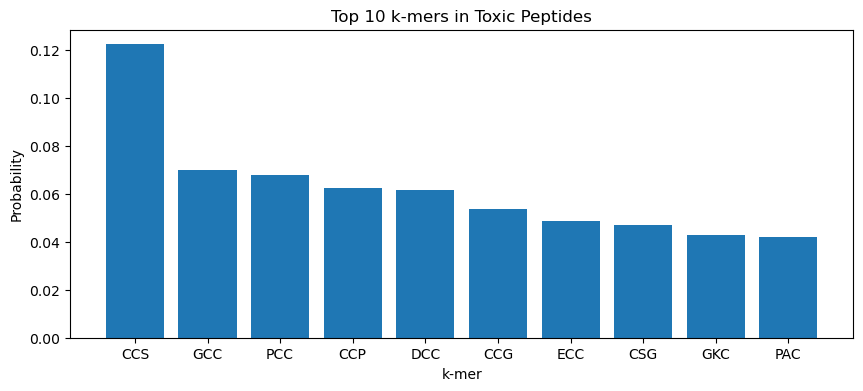

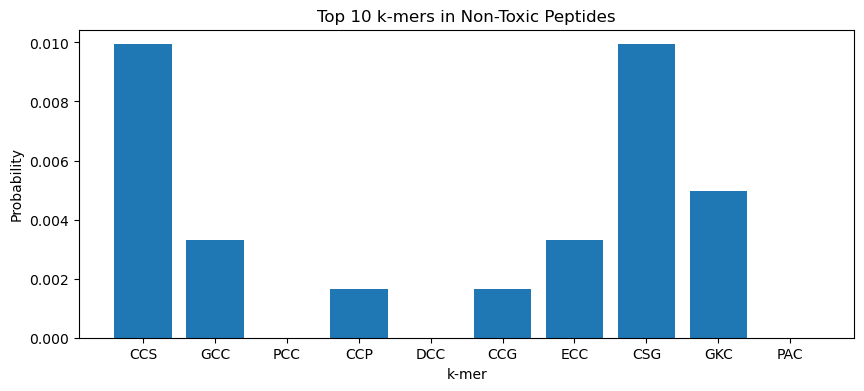

In [3]:
# 3. Determine the top 10 k-mers with the highest probabilities of appearing in a toxic peptide.
# Plot the probabilities for these top 10 k-mers to appear in a toxic peptide and also 
# plot the probabilities for these same top 10 k-mers to appear in a non-toxic peptide.

present = pd.DataFrame((X.toarray() > 0), columns=kmer_names)

toxic_probs = present[y == True].mean()
non_toxic_probs = present[y == False].mean()

top_10 = toxic_probs.sort_values(ascending=False).head(10).index

plt.figure(figsize=(10.1, 4))
plt.bar(top_10, toxic_probs[top_10])
plt.xlabel("k-mer")
plt.ylabel("Probability")
plt.title("Top 10 k-mers in Toxic Peptides")
plt.show()

print()

plt.figure(figsize=(10, 4))
plt.bar(top_10, non_toxic_probs[top_10])
plt.xlabel("k-mer")
plt.ylabel("Probability")
plt.title("Top 10 k-mers in Non-Toxic Peptides")
plt.show()

In [4]:
# 4. Split the dataset into training and testing subsets. 
# 70% of the data should be used for training, whereas 
# the remaining 30% will be used for testing.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

In [5]:
# 5. Train a Logistic Regression model using the default Scikit-Learn parameters.

log_model = LogisticRegression()
log_model.fit(X_train, y_train)

LogisticRegression()

In [6]:
# 6. Train a Support Vector Classifier using the default Scikit-Learn parameters.

svc_model = SVC()
svc_model.fit(X_train, y_train)

SVC()

In [7]:
# 7. For both models, compute the confusion matrix on the testing dataset, 
# and use the confusion matrix to compute accuracy, precision, and recall.

def model_results(model, name):
    y_pred = model.predict(X_test)

    cm = metrics.confusion_matrix(y_test, y_pred, labels=[False, True])
    tn, fp, fn, tp = cm.ravel()

    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)

    cm_table = pd.DataFrame(
        cm,
        index=["Actual Non-Toxic", "Actual Toxic"],
        columns=["Predicted Non-Toxic", "Predicted Toxic"]
    )

    scores = pd.DataFrame({
        "Model": [name],
        "Accuracy": [accuracy],
        "Precision": [precision],
        "Recall": [recall]
    })

    return cm_table, scores

log_cm, log_scores = model_results(log_model, "Logistic Regression")
svc_cm, svc_scores = model_results(svc_model, "Support Vector Classifier")

print("Logistic Regression Confusion Matrix")
display(log_cm)

print("\n \n Support Vector Classifier Confusion Matrix")
display(svc_cm)

print()
print()

pd.concat([log_scores, svc_scores], ignore_index=True)

Logistic Regression Confusion Matrix


,Predicted Non-Toxic,Predicted Toxic
Actual Non-Toxic,78,103
Actual Toxic,38,381



 
 Support Vector Classifier Confusion Matrix


,Predicted Non-Toxic,Predicted Toxic
Actual Non-Toxic,31,150
Actual Toxic,10,409


,Model,Accuracy,Precision,Recall
0,Logistic Regression,0.765000,0.787190,0.909308
1,Support Vector Classifier,0.733333,0.731664,0.976134


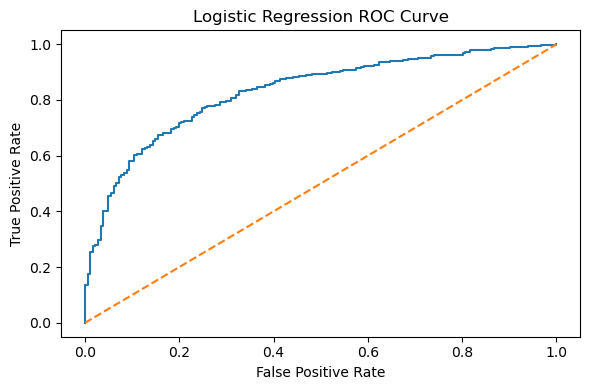

Logistic Regression Area Under Curve:  0.83 




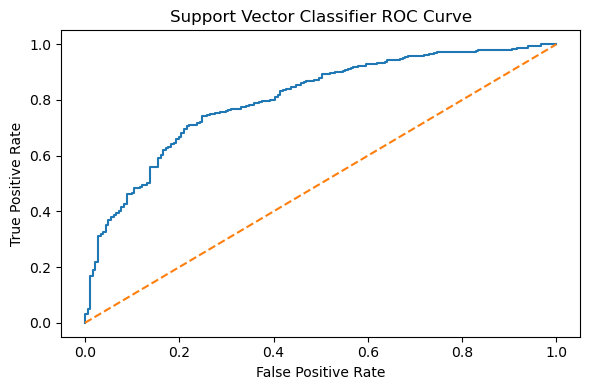

Support Vector Classifier Area Under Curve: 0.802


In [8]:
# 8. For both models, produce a plot of the receiver operating characteristic (ROC) 
# and compute the area under the ROC curve.


log_scores = log_model.decision_function(X_test)
svc_scores = svc_model.decision_function(X_test)

log_fpr, log_tpr, _ = metrics.roc_curve(y_test, log_scores)
svc_fpr, svc_tpr, _ = metrics.roc_curve(y_test, svc_scores)

log_auc = metrics.auc(log_fpr, log_tpr)
svc_auc = metrics.auc(svc_fpr, svc_tpr)

plt.figure(figsize=(6, 4))
plt.plot(log_fpr, log_tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression ROC Curve")
plt.tight_layout()
plt.show()

print("Logistic Regression Area Under Curve: ", round(log_auc, 3), "\n\n")

plt.figure(figsize=(6, 4))
plt.plot(svc_fpr, svc_tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Support Vector Classifier ROC Curve")
plt.tight_layout()
plt.show()

print("Support Vector Classifier Area Under Curve:", round(svc_auc, 3))

In [9]:
# 9. There are 3,306 antimicrobial peptides (AMPs) from the Antimicrobial Peptide Database (available in FASTA format above).
# These AMPs are found naturally from a variety of organisms. 
# How many AMPs sequences are predicted to be toxic by either of your models (and therefore are expected to be unsuitable AMPs for human use)?

def read_fasta(filename):
    sequences = []
    current_seq = ""

    with open(filename) as file:
        for line in file:
            line = line.strip()

            if line.startswith(">"):
                if current_seq:
                    sequences.append(current_seq)
                    current_seq = ""
            else:
                current_seq += line

    if current_seq:
        sequences.append(current_seq)

    return sequences


fasta_file = "natural_amps.fasta"

amp_sequences = read_fasta(fasta_file)

X_amp = vectorizer.transform(amp_sequences)

log_predictions = log_model.predict(X_amp)
svc_predictions = svc_model.predict(X_amp)

toxic_by_either_model = (log_predictions == True) | (svc_predictions == True)
num_toxic_amps = toxic_by_either_model.sum()

print("AMP sequences predicted toxic by either model:", num_toxic_amps)

AMP sequences predicted toxic by either model: 2945


# 10. Write a brief report (2-3 paragraphs) that summarizes each of the analyses you performed and their results.

For this project, I started by loading the toxic peptide dataset, which had 2,000 peptide sequences. I converted each sequence into overlapping 3-mers and used the 3-mer counts as the features for the models. I also looked at which 3-mers had the highest probability of showing up in toxic peptides, then compared those same 3-mers in the non-toxic peptides using separate plots.

I split the data into 70% training and 30% testing, then trained two models: Logistic Regression and a Support Vector Classifier. On the testing data, Logistic Regression had an accuracy of 0.765, precision of 0.787, recall of 0.909, and an AUC of 0.830. The Support Vector Classifier had an accuracy of 0.733, precision of 0.732, recall of 0.976, and an AUC of 0.802. Based on these results, Logistic Regression performed a little better overall, but the SVC had the higher recall, meaning it caught more of the toxic peptides.

Lastly, I used both trained models on the natural AMP sequences from the FASTA file. I counted a sequence as toxic if either model predicted it as toxic. Using that approach, 2,945 AMP sequences were predicted to be toxic, which means they would be considered potentially unsuitable for human use based on these models.
